# SeismicDataset. Подготовка сейсмического датасета #

## 1.3. Точность расчёта и выбор размера и порядка элемента ##

Какой порядок при размере элемента около 10 м сохраняет точность поверхностных записей при приемлемой стоимости?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import mapping, number, read_json

### От распределённой силы к точечному источнику ###

Переход к узловой силе Рикера 30 Гц потребовал новой проверки. Для обеих геометрий №12404 и №65 при x=350 м сравнили p4 и p5, затем добавили p3 и контроли с половинным шагом. Ближайший приёмник чувствителен к дискретизации сосредоточенной силы. Поэтому отдельно рассматриваем полную линию и приёмники дальше 20 м. Исключение ближних трасс меняет смысл нормы.

In [2]:
primary = read_json((ROOT / "data/dev_1_3_point_source/central_cu_v1/acceptance_v1/acceptance.json"))
extra = read_json((ROOT / "data/dev_1_3_point_source/central_p3_cu_v1/p3_report_v1/p3_report.json"))
print("Основные и временные контроли p4/p5:", primary["completed_input_runs"])
print("Дополнительные p3, основные и временные:", extra["expected_new_main_runs"], extra["expected_new_time_controls"])

Основные и временные контроли p4/p5: 12
Дополнительные p3, основные и временные: 4 4


### Сравнение на одной квадратичной геометрии ###

Для сетки с шагом около 10 м построили точное разбиение каждой Q2-ячейки на 2×2. Опора — p5 на уточнённой сетке. Для каждого номера сравнивались общие положения приёмников и общий шаг времени, β=1/27. Таблица даёт относительную L2 совместных Vx/Vy за 0,5–1 с по выборке из 70 приёмников после исключения ближней зоны 20 м, в процентах.

№12404: p5 0.247373%   p6 0.007739%   p7 0.000566%
№00065: p5 0.363185%   p6 0.041341%   p7 0.005288%


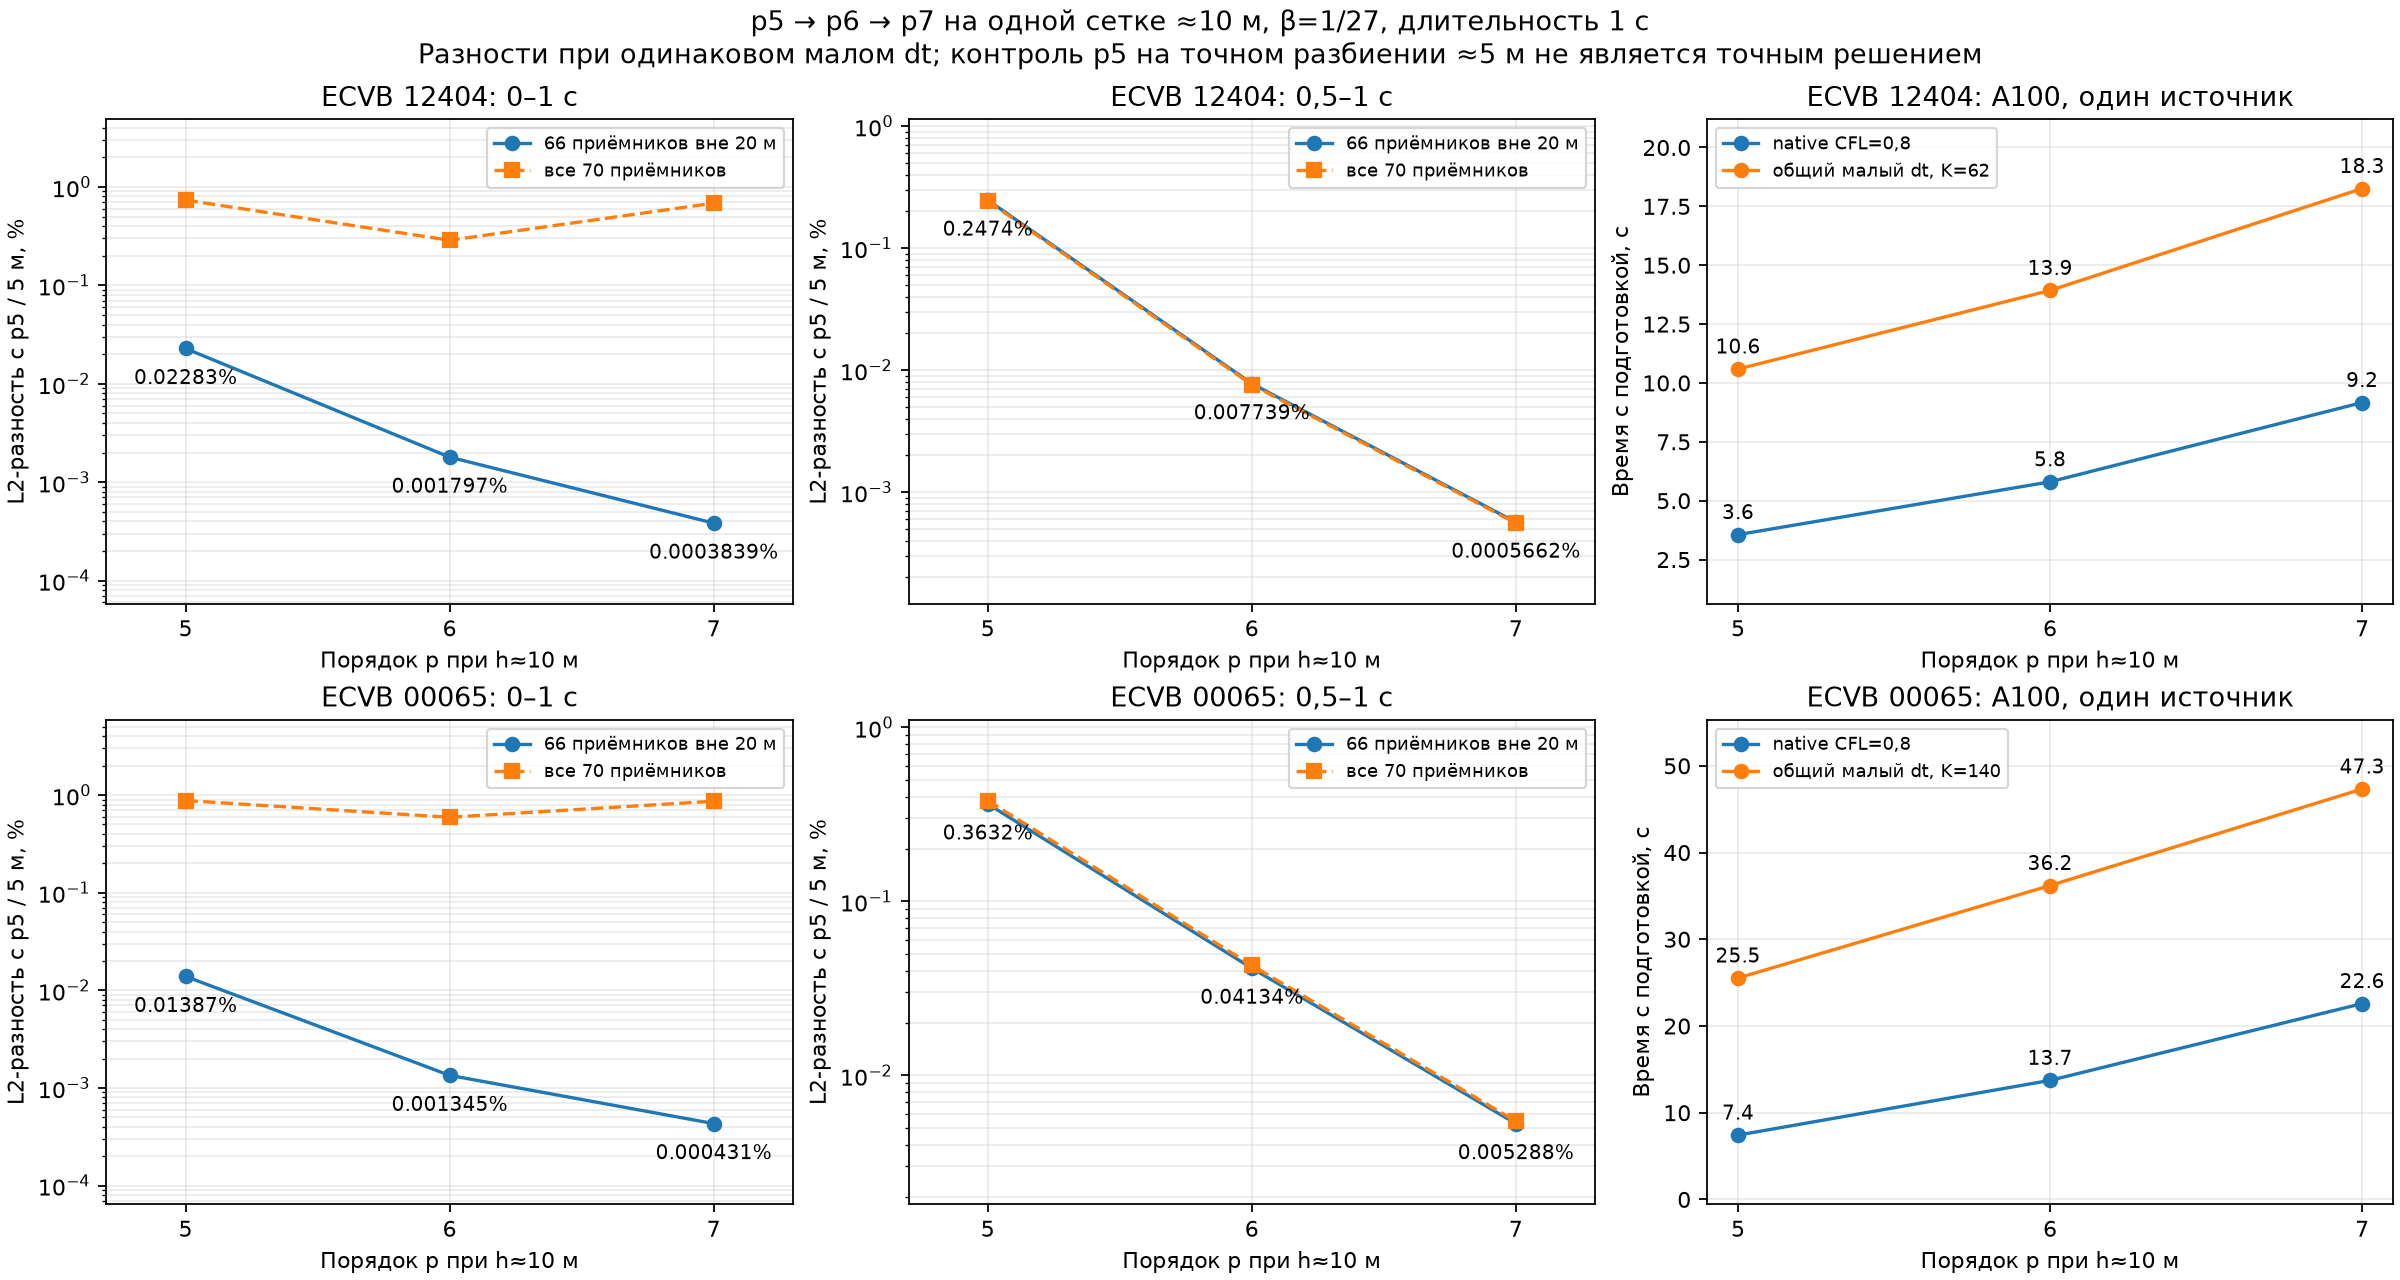

In [3]:
models = read_json((ROOT / "data/dev_1_4_server_preparation/coarse_order_v1/p5_coarse_analysis_v1/analysis.json"))["models"]
for case_id, record in mapping(models).items():
    pairs = mapping(mapping(record)["pairs"])
    differences = [number(mapping(mapping(pairs[f"p{order}/reference"])["dataset70_far20/late"])["relative_l2"]) for order in (5, 6, 7)]
    print(f"№{int(case_id):05d}: " + "   ".join(f"p{p} {100*d:.6f}%" for p, d in zip((5, 6, 7), differences)))

display(Image(filename=str(ROOT / "img/dev_1_4_server_preparation/coarse_order_v1/p5_coarse_analysis_v1/convergence.png"), width=850))

### Две сетки при 30 Гц ###

Здесь и далее источник точечный, с амплитудой 1 Н/м вниз и максимумом Рикера в 0,05 с. Переход от 15 к 30 Гц вдвое уменьшил длины волн при тех же скоростях. Поэтому выбор порядка по раннему пилоту пересмотрели. В таблице собраны обе ветви опыта на общих шагах времени для каждого ID. Столбцы содержат относительные нормы по удалённым приёмникам за 0,5–1 с. Опорой для обеих сеток служит p5/5 м.

In [4]:
from IPython.display import Markdown

fine = mapping(read_json(ROOT / "data/dev_1_4_server_preparation/coarse_order_v1/analysis_v1/analysis.json")["models"])
table = ["| h, м | p | ECVB12404, % | ECVB00065, % |", "|---:|---:|---:|---:|"]
for step, order in ((5, 3), (5, 4), (5, 5), (10, 5), (10, 6), (10, 7)):
    values = []
    for model_id in ("12404", "65"):
        if (step, order) == (5, 5):
            values.append("опора")
            continue
        series = fine if step == 5 else mapping(models)
        key = next(k for k in series if int(k) == int(model_id))
        pair_key = f"p{order}/fixed" if step == 5 else f"p{order}/reference"
        entry = mapping(mapping(mapping(series[key])["pairs"])[pair_key])
        error = number(mapping(entry["dataset70_far20/late"])["relative_l2"])
        values.append(f"{100 * error:.6f}".replace(".", ","))
    table.append(f"| {step} | {order} | " + " | ".join(values) + " |")
display(Markdown("\n".join(table)))

| h, м | p | ECVB12404, % | ECVB00065, % |
|---:|---:|---:|---:|
| 5 | 3 | 0,303558 | 0,703934 |
| 5 | 4 | 0,007959 | 0,031252 |
| 5 | 5 | опора | опора |
| 10 | 5 | 0,247373 | 0,363185 |
| 10 | 6 | 0,007739 | 0,041341 |
| 10 | 7 | 0,000566 | 0,005288 |

На сетке 5 м p4 даёт позднюю разность 0,0080% и 0,0313% относительно p5. На сетке 10 м близкий уровень обеспечивает p6, а p7 сближает обе сетки ещё примерно на порядок. В дополнительном опыте на двухслойной модели с PML350 опору повысили до p9/5 м. При общем шаге K78 удалённые относительные разности для p4/5 м, p5/5 м, p6/10 м и p7/10 м составили соответственно 0,000306%, 0,0000105%, 0,0000461% и 0,00000663%. Это отдельная серия со своими приёмниками и нормой. [Контроль по p8 и p9](data/dev_1_5_geometry_frequency/pml_fixed_orders_v1/analysis/metrics.json).

### Независимый ориентир по задаче Лэмба ###

Е. М. Уханов сравнивал поверхностную скорость с аналитическим решением задачи Лэмба в однородной среде. Для разных порядков он подобрал размеры элемента, при которых расхождение по пику составляло менее 1%. Ниже воспроизведены рис. 33 и таблица со с. 48. EPW — число элементов на длину волны Рэлея, PPW — число узловых интервалов на ту же длину. При степени p в одном направлении PPW = p · EPW. [Курсовая работа Уханова, 2025](ref/Uhanov_2025_Lamb.pdf).

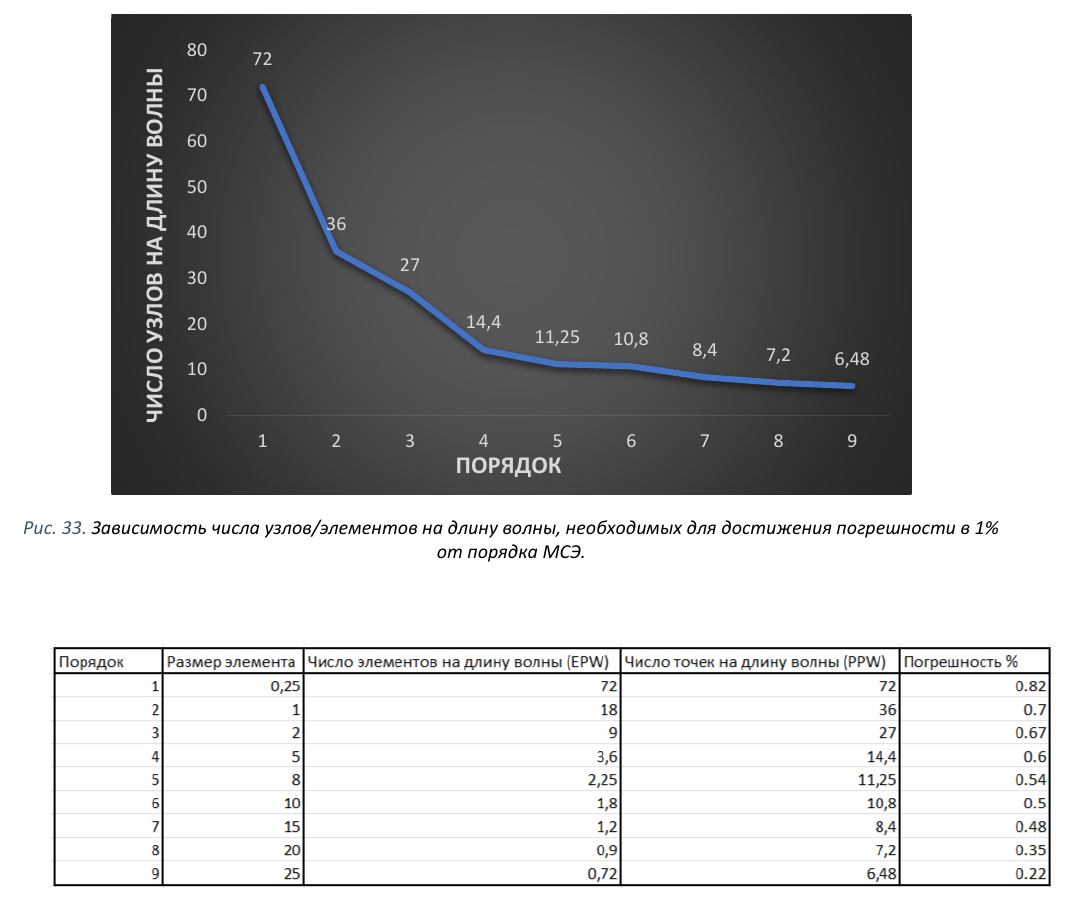

In [5]:
display(Image(filename=str(ROOT / "img/dev_1_3_point_source/uhanov_fig33_table.png"), width=850))

| Порядок | PPW Рэлея у Уханова | Ошибка у Уханова, % | Наша сетка, м | PPW для S-волны при 30 Гц |
|---:|---:|---:|---:|---:|
| 4 | 14,4 | 0,60 | 5 | 16,42 |
| 5 | 11,25 | 0,54 | 5 | 20,52 |
| 6 | 10,8 | 0,50 | 10 | 12,31 |
| 7 | 8,4 | 0,48 | 10 | 14,37 |

В последнем столбце использованы p · Vs/(30h) и минимум Vs = 615,71 м/с по всем исходным моделям. Длина S-волны на основной частоте равна 20,52 м. При переходе p4/5 м → p6/10 м число интервалов на волну снижается, но порядок внутри элемента возрастает. Обе серии подтверждают, что требуемое PPW зависит от p. Численный порог Уханова нельзя переносить буквально: у него рэлеевская волна и ошибка трассы относительно аналитики, у нас импульс с полосой частот, неоднородные среды и норма разности с уточнённым расчётом.

### Выбор для серии ###

Переход p5→p6 уменьшил позднюю разность с опорой с 0,247% до 0,00774% у №12404 и с 0,363% до 0,0413% у №65. При p7 разность продолжила уменьшаться. Выбран p6/10 м: в измерениях с собственным шагом CFL он примерно в 1,7 раза быстрее p4 на вдвое более мелкой сетке. Опора p5 имеет собственную погрешность. На ранних ближних трассах сходимость немонотонна, а на обеих моделях вывод о точности относится к исследованным окнам и положениям источника.

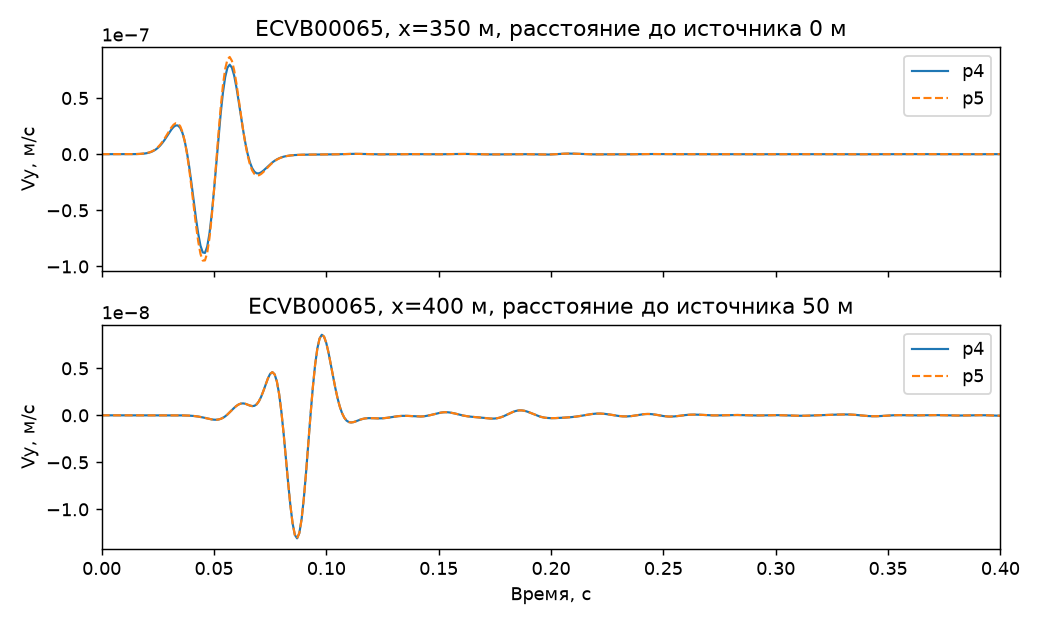

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
case = ROOT / "data/dev_1_3_point_source/central_cu_v1/00065/curved"
for order, style in ((4, "-"), (5, "--")):
    with np.load(case / f"p{order}/x350/surface.npz", allow_pickle=False) as traces:
        xy = traces["coordinates_m"]
        vy = traces["velocity_m_s"][:, :, 1]
        for axis, x in zip(axes, (350, 400), strict=True):
            receiver, = np.flatnonzero(np.isclose(xy[:, 0], x))
            axis.plot(traces["time_s"], vy[:, receiver], style, label=f"p{order}", linewidth=1.2)
            axis.set_title(f"ECVB00065, x={x} м, расстояние до источника {x-350} м")
            axis.set_ylabel("Vy, м/с")
            axis.legend(loc="upper right")
axes[-1].set(xlim=(0, .4), xlabel="Время, с")
fig.tight_layout()
fig.savefig(ROOT / "img/dev_1_3_point_source/near_source_traces.png", dpi=130)
plt.close(fig)

display(Image(filename=str(ROOT / "img/dev_1_3_point_source/near_source_traces.png"), width=850))

### Вывод ###

Для массовой постановки выбран p6 при h≈10 м. На двух пилотах поздняя удалённая разность с уточнённой опорой укладывалась в 0,042%. Ближняя зона точечного источника требует отдельной интерпретации.